# 01 — Preprocessing Dataset E-Nose (TS1–TS5)

Lima rekaman pembusukan daging sapi (TS1–TS5), masing-masing 2.160 menit.

Hasil akhir: `dataset_train` (TS1–TS4) dan `dataset_test` (TS5) siap untuk K-Means. Di akhir notebook, keduanya diunduh sebagai zip berisi CSV.

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 90

## Konfigurasi

Di Colab akan muncul tombol *Choose Files*: pilih file zip dataset.

In [2]:
ZIP_NAME = 'e-nose dataset in uncontrolled ambient conditions (1).zip'

try:
    from google.colab import files       # hanya ada di Google Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Muncul tombol "Choose Files": pilih file zip dataset dari laptop
    uploaded = files.upload()
    zips = [name for name in uploaded if name.lower().endswith('.zip')]
    if not zips:
        raise FileNotFoundError('Yang diunggah bukan file .zip. Jalankan sel ini lagi dan pilih zip dataset.')
    DATA_ZIP = Path(zips[0])
else:
    # Jalan di laptop: zip ada di folder proyek (satu tingkat di atas folder notebook)
    DATA_ZIP = Path('..') / ZIP_NAME

print('Dataset:', DATA_ZIP)

SENSORS = ['MQ135', 'MQ136', 'MQ2', 'MQ3', 'MQ4', 'MQ5', 'MQ6', 'MQ8', 'MQ9']
ENV = ['Humidity', 'Temperature']
LABELS = ['class', 'TVC']

BASELINE_MINUTES = (1, 60)   # rentang menit untuk nilai acuan
USE_BASELINE_RATIO = True
TRAIN_SERIES = ['TS1', 'TS2', 'TS3', 'TS4']
TEST_SERIES = ['TS5']
CLASS_ORDER = ['excellent', 'good', 'acceptable', 'spoiled']

Saving e-nose dataset in uncontrolled ambient conditions (1).zip to e-nose dataset in uncontrolled ambient conditions (1).zip
Dataset: e-nose dataset in uncontrolled ambient conditions (1).zip


## 1. Baca kelima file dari zip

In [3]:
frames = []
with zipfile.ZipFile(DATA_ZIP) as z:
    for name in sorted(z.namelist()):
        if not name.lower().endswith('.csv'):
            continue
        with z.open(name) as f:
            d = pd.read_csv(f)
        d['series'] = Path(name).stem      # TS1 ... TS5
        frames.append(d)
        print(f'{name}: {d.shape[0]} baris, {d.shape[1]-1} kolom')

raw = {d['series'].iloc[0]: d for d in frames}
frames[0].head()

TS1.csv: 2160 baris, 14 kolom
TS2.csv: 2160 baris, 14 kolom
TS3.csv: 2160 baris, 14 kolom
TS4.csv: 2160 baris, 14 kolom
TS5.csv: 2160 baris, 14 kolom


,minute,class,TVC,MQ135,MQ136,MQ2,MQ3,MQ4,MQ5,MQ6,MQ8,MQ9,Humidity,Temperature,series
0,1,excellent,2.567112,22.86,41.24,29.56,14.83,49.38,11.10,2.21,32.09,14.29,55.1,34.6,TS1
1,2,excellent,2.567112,22.75,41.50,29.72,14.83,49.38,11.23,2.23,31.92,14.58,55.1,34.6,TS1
2,3,excellent,2.567112,22.75,41.50,29.72,14.83,49.38,11.28,2.22,34.31,14.40,55.1,34.6,TS1
3,4,excellent,2.567112,22.86,42.56,29.56,14.77,49.38,11.46,2.22,34.12,14.64,55.4,34.5,TS1
4,5,excellent,2.567112,23.07,42.03,29.56,14.83,49.38,11.46,2.22,33.93,14.58,55.4,34.4,TS1


## 2. Cek kualitas data

In [4]:
df = pd.concat(frames, ignore_index=True)

print('Ukuran gabungan     :', df.shape)
print('Nilai kosong        :', int(df.isna().sum().sum()))
print('Duplikat baris penuh:', int(df.duplicated().sum()))
print('Duplikat (series, minute):', int(df.duplicated(['series', 'minute']).sum()))
print('Nilai sensor <= 0   :', int((df[SENSORS] <= 0).sum().sum()))
print()
print(df.groupby('series')['minute'].agg(['min', 'max', 'count']))
print()
print(df.dtypes)

Ukuran gabungan     : (10800, 15)
Nilai kosong        : 0
Duplikat baris penuh: 0
Duplikat (series, minute): 0
Nilai sensor <= 0   : 0

        min   max  count
series                  
TS1       1  2160   2160
TS2       1  2160   2160
TS3       1  2160   2160
TS4       1  2160   2160
TS5       1  2160   2160

minute           int64
class           object
TVC            float64
MQ135          float64
MQ136          float64
MQ2            float64
MQ3            float64
MQ4            float64
MQ5            float64
MQ6            float64
MQ8            float64
MQ9            float64
Humidity       float64
Temperature    float64
series          object
dtype: object


In [5]:
df[SENSORS + LABELS[1:] + ENV].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MQ135,10800.0,7.72,5.14,3.63,4.86,5.59,7.69,27.55
MQ136,10800.0,17.62,24.79,1.13,2.17,6.24,12.89,77.13
MQ2,10800.0,4.50,5.39,1.03,2.65,2.91,3.52,45.76
MQ3,10800.0,8.56,4.15,3.84,5.28,7.37,10.33,25.88
MQ4,10800.0,10.30,11.52,0.55,1.08,4.50,18.48,49.77
MQ5,10800.0,16.52,23.25,1.87,2.84,4.43,16.71,81.41
MQ6,10800.0,18.27,18.84,2.06,7.16,9.58,19.71,100.52
MQ8,10800.0,12.00,13.42,1.74,2.60,3.89,18.79,56.63
MQ9,10800.0,7.64,3.27,3.64,5.20,6.90,9.04,17.34
TVC,10800.0,4.21,0.92,2.23,3.39,4.88,4.96,5.10


## 3. Gabungkan menjadi satu dataset

In [6]:
data = df[['series', 'minute'] + SENSORS + ENV + LABELS].copy()
data['series'] = pd.Categorical(data['series'], categories=TRAIN_SERIES + TEST_SERIES, ordered=True)
data['class'] = pd.Categorical(data['class'], categories=CLASS_ORDER, ordered=True)
data = data.sort_values(['series', 'minute']).reset_index(drop=True)
print(data.shape)
data.head()

(10800, 15)


,series,minute,MQ135,MQ136,MQ2,MQ3,MQ4,MQ5,MQ6,MQ8,MQ9,Humidity,Temperature,class,TVC
0,TS1,1,22.86,41.24,29.56,14.83,49.38,11.10,2.21,32.09,14.29,55.1,34.6,excellent,2.567112
1,TS1,2,22.75,41.50,29.72,14.83,49.38,11.23,2.23,31.92,14.58,55.1,34.6,excellent,2.567112
2,TS1,3,22.75,41.50,29.72,14.83,49.38,11.28,2.22,34.31,14.40,55.1,34.6,excellent,2.567112
3,TS1,4,22.86,42.56,29.56,14.77,49.38,11.46,2.22,34.12,14.64,55.4,34.5,excellent,2.567112
4,TS1,5,23.07,42.03,29.56,14.83,49.38,11.46,2.22,33.93,14.58,55.4,34.4,excellent,2.567112


### Peran setiap kolom

| Kolom | Peran |
|---|---|
| 9 sensor MQ, Humidity, Temperature | Kandidat fitur |
| series, minute | Penanda (bukan fitur) |
| class, TVC | Label validasi (bukan fitur) |

## 4. Normalisasi per series

Nilai sensor dibagi median menit 1–60 series-nya (setara Rs/R0), lalu di-log. Humidity dan Temperature tidak dinormalisasi.

In [7]:
lo, hi = BASELINE_MINUTES
base_mask = data['minute'].between(lo, hi)
baseline = data[base_mask].groupby('series', observed=True)[SENSORS].median()
print(f'Baseline (median menit {lo}-{hi}) per series:')
baseline.round(2)

Baseline (median menit 1-60) per series:


,MQ135,MQ136,MQ2,MQ3,MQ4,MQ5,MQ6,MQ8,MQ9
series,,,,,,,,,
TS1,24.06,37.88,28.02,14.77,48.60,8.05,2.21,32.27,15.06
TS2,13.94,14.71,29.87,16.72,29.83,40.38,35.40,40.54,9.57
TS3,23.23,18.94,37.69,17.56,39.83,38.18,33.47,39.79,12.98
TS4,14.14,13.63,4.36,15.20,39.70,33.73,27.30,45.26,12.92
TS5,16.73,69.64,6.80,17.26,37.73,21.03,22.22,49.17,15.31


In [8]:
ratio = data[SENSORS] / baseline.loc[data['series']].to_numpy()
log_ratio = np.log(ratio)

if USE_BASELINE_RATIO:
    sensor_feats = log_ratio.add_prefix('lr_')
else:
    sensor_feats = data[SENSORS].add_prefix('raw_')

# Semua kandidat fitur: 9 sensor + suhu & kelembapan (tidak ada yang dihapus)
features_all = pd.concat([sensor_feats, data[ENV]], axis=1)

prep = pd.concat([data[['series', 'minute'] + LABELS], features_all], axis=1)
prep.head()

,series,minute,class,TVC,lr_MQ135,lr_MQ136,lr_MQ2,lr_MQ3,lr_MQ4,lr_MQ5,lr_MQ6,lr_MQ8,lr_MQ9,Humidity,Temperature
0,TS1,1,excellent,2.567112,-0.051162,0.084985,0.053504,0.004054,0.015922,0.321273,0.000000,-0.005594,-0.052482,55.1,34.6
1,TS1,2,excellent,2.567112,-0.055986,0.091270,0.058902,0.004054,0.015922,0.332917,0.009009,-0.010905,-0.032391,55.1,34.6
2,TS1,3,excellent,2.567112,-0.055986,0.091270,0.058902,0.004054,0.015922,0.337359,0.004515,0.061299,-0.044814,55.1,34.6
3,TS1,4,excellent,2.567112,-0.051162,0.116492,0.053504,0.000000,0.015922,0.353191,0.004515,0.055746,-0.028285,55.4,34.5
4,TS1,5,excellent,2.567112,-0.042018,0.103960,0.053504,0.004054,0.015922,0.353191,0.004515,0.050162,-0.032391,55.4,34.4


### Rentang tiap fitur per series

In [9]:
fcols = list(features_all.columns)
prep.groupby('series', observed=True)[fcols].agg(['min', 'median', 'max']).T.round(2).unstack(level=1)

series         TS1                  TS2                  TS3                  TS4                  TS5              
               min median    max    min median    max    min median    max    min median    max    min median    max
lr_MQ135     -1.81  -1.60   0.14  -1.18  -0.90   0.28  -1.71  -1.52   0.08  -1.36  -0.93   0.48  -1.31  -0.98   0.09
lr_MQ136     -3.51  -2.94   0.12  -2.34  -1.89   0.31  -2.52  -1.72   0.09  -1.03  -0.75   0.15  -0.42   0.00   0.10
lr_MQ2       -2.72  -2.45   0.06  -2.71  -2.29   0.08  -2.70  -2.64   0.19  -1.44  -0.45   1.95  -1.11  -0.69   1.26
lr_MQ3       -1.29  -0.92   0.56  -1.28  -0.75   0.19  -1.43  -1.14   0.10  -1.38  -1.02   0.22  -1.02  -0.64   0.37
lr_MQ4       -3.62  -2.96   0.02  -3.66  -1.35   0.14  -3.85  -3.66   0.17  -4.28  -3.37   0.16  -3.39  -0.58   0.18
lr_MQ5       -0.75   2.18   2.31  -2.77  -2.27   0.13  -2.97  -2.65   0.11  -2.89  -2.63   0.10  -1.81  -1.36   0.10
lr_MQ6       -0.07   3.35   3.82  -1.75  -1.24   0.48  -1.84  -1.48   0.36  -2.12  -1.66   0.31  -1.21  -0.82   0.27
lr_MQ8       -2.38  -1.17   0.14  -2.99  -2.31   0.20  -2.88  -2.45   0.25  -3.26  -2.83   0.15  -3.14  -2.88   0.14
lr_MQ9       -1.41  -1.09   0.14  -0.91  -0.50   0.21  -1.25  -0.65   0.04  -1.27  -0.59   0.13  -0.86  -0.54   0.05
Humidity     55.10  78.20  86.00  40.90  65.40  81.80  56.90  93.40  99.90  46.70  99.90  99.90  56.60  93.40  98.80
Temperature  33.50  38.40  39.80  29.10  32.40  33.50  29.50  33.70  37.80  29.20  33.50  38.70  30.00  33.90  39.80

## 5. Korelasi (Spearman)

TVC dan kelas (`class_ord`: excellent = 0 … spoiled = 3) ikut ditampilkan, tetapi bukan fitur K-Means.

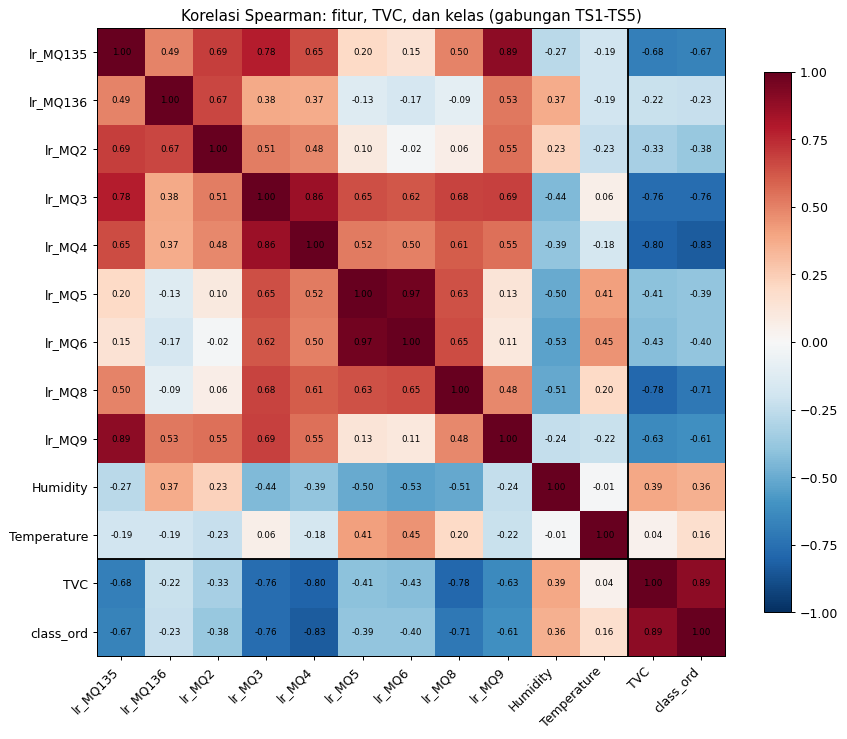

,level_0,level_1,r,abs_r
40,lr_MQ5,lr_MQ6,0.968,0.968
7,lr_MQ135,lr_MQ9,0.895,0.895
27,lr_MQ3,lr_MQ4,0.855,0.855
2,lr_MQ135,lr_MQ3,0.783,0.783
1,lr_MQ135,lr_MQ2,0.690,0.690
31,lr_MQ3,lr_MQ9,0.687,0.687
30,lr_MQ3,lr_MQ8,0.678,0.678
10,lr_MQ136,lr_MQ2,0.671,0.671
45,lr_MQ6,lr_MQ8,0.649,0.649
3,lr_MQ135,lr_MQ4,0.649,0.649


In [10]:
eda_cols = fcols + ['TVC', 'class_ord']
eda = prep.assign(class_ord=prep['class'].cat.codes)[eda_cols]
corr_all = eda.corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr_all, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(eda_cols)), eda_cols, rotation=45, ha='right')
ax.set_yticks(range(len(eda_cols)), eda_cols)
for i in range(len(eda_cols)):
    for j in range(len(eda_cols)):
        ax.text(j, i, f'{corr_all.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
# garis pemisah antara fitur dan label
n = len(fcols) - 0.5
ax.axhline(n, color='k', lw=1.5); ax.axvline(n, color='k', lw=1.5)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Korelasi Spearman: fitur, TVC, dan kelas (gabungan TS1-TS5)')
fig.tight_layout(); plt.show()

# pasangan antarfitur yang paling mirip (redundansi)
corr = corr_all.loc[fcols, fcols]
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename('r').reset_index()
             .assign(abs_r=lambda t: t['r'].abs())
             .sort_values('abs_r', ascending=False))
pairs.head(10).round(3)

**Interpretasi heatmap korelasi**

*Hubungan bakteri (TVC) dengan sensor (dua kolom paling kanan):*
- **Makin banyak bakteri, makin kecil nilai sensor.** Korelasi TVC paling kuat dengan MQ4 (−0,80), MQ8 (−0,78), MQ3 (−0,76), MQ135 (−0,68), dan MQ9 (−0,63). Nilai sensor MOS turun ketika gas bertambah, jadi hasil ini menunjukkan **pertumbuhan bakteri sejalan dengan bertambahnya gas berbau** yang terdeteksi sensor.
- Hubungan sedang: MQ5 (−0,41) dan MQ6 (−0,43). Hubungan lemah: MQ2 (−0,33) dan MQ136 (−0,22). Kedua sensor terakhir kurang mencerminkan pembusukan di dataset ini.
- Pola `class_ord` hampir sama dengan TVC (MQ4 −0,83), karena kelas kualitas daging memang ditentukan dari TVC (TVC–class_ord = 0,89).
- **Kelembapan ikut naik bersama TVC (0,39)**, sedangkan **suhu hampir tidak berhubungan dengan TVC (0,04)**.
- Catatan: korelasi bukan sebab-akibat. TVC dan nilai sensor sama-sama berubah seiring waktu, dan TVC hanya diukur tiap jam (bentuk tangga). Tetapi arah dan kekuatannya konsisten dengan proses pembusukan menghasilkan bau.

*Hubungan antarfitur:*
- **MQ5 dan MQ6 hampir kembar (0,97)**, lalu **MQ135–MQ9 (0,89)** dan **MQ3–MQ4 (0,86)**. Pasangan ini membawa informasi yang mirip; jika semuanya dipakai, informasi yang sama terhitung dua kali dalam jarak K-Means.
- **MQ5 dan MQ6 berkorelasi sedang dengan suhu (0,41 dan 0,45)**, sejalan dengan TS1 yang suhunya paling tinggi dan MQ5/MQ6-nya naik.
- **Kelembapan berkorelasi negatif dengan sebagian besar sensor** (−0,24 sampai −0,53). Sensor MOS memang terpengaruh kelembapan, tetapi kelembapan juga naik seiring waktu, sehingga efeknya sulit dipisahkan dari pembusukan.
- **Suhu dan kelembapan tidak saling berkorelasi (−0,01)**, jadi keduanya membawa informasi berbeda.

Tidak ada variabel yang dihapus. TVC dan `class` tetap disimpan di dataset untuk validasi, dan temuan ini menjadi dasar perbandingan set fitur saat modeling.

In [11]:
# Korelasi tiap fitur terhadap TVC, menit, kelembapan, dan suhu (Spearman, gabungan)
pd.DataFrame({
    'vs_TVC': prep[fcols].corrwith(prep['TVC'], method='spearman'),
    'vs_minute': prep[fcols].corrwith(prep['minute'], method='spearman'),
    'vs_Humidity': prep[fcols].corrwith(prep['Humidity'], method='spearman'),
    'vs_Temperature': prep[fcols].corrwith(prep['Temperature'], method='spearman'),
}).round(2).sort_values('vs_TVC')

,vs_TVC,vs_minute,vs_Humidity,vs_Temperature
lr_MQ4,-0.80,-0.82,-0.39,-0.18
lr_MQ8,-0.78,-0.70,-0.51,0.20
lr_MQ3,-0.76,-0.76,-0.44,0.06
lr_MQ135,-0.68,-0.64,-0.27,-0.19
lr_MQ9,-0.63,-0.59,-0.24,-0.22
lr_MQ6,-0.43,-0.42,-0.53,0.45
lr_MQ5,-0.41,-0.41,-0.50,0.41
lr_MQ2,-0.33,-0.38,0.23,-0.23
lr_MQ136,-0.22,-0.22,0.37,-0.19
Temperature,0.04,0.19,-0.01,1.00


## 6. Pembagian data

TS1–TS4 untuk membentuk cluster, TS5 untuk uji.

In [12]:
train = prep[prep['series'].isin(TRAIN_SERIES)].reset_index(drop=True)
test = prep[prep['series'].isin(TEST_SERIES)].reset_index(drop=True)
print('train:', train.shape, ' test:', test.shape)

train: (8640, 15)  test: (2160, 15)


## 7. Standarisasi

Scaler di-*fit* pada TS1–TS4 saja, lalu dipakai untuk TS5 (mencegah kebocoran data).

In [13]:
scaler = StandardScaler().fit(train[fcols])
Z_train = pd.DataFrame(scaler.transform(train[fcols]), columns=fcols)
Z_test = pd.DataFrame(scaler.transform(test[fcols]), columns=fcols)

pd.DataFrame({'mean_TS1-4': scaler.mean_, 'std_TS1-4': scaler.scale_}, index=fcols).round(4)

,mean_TS1-4,std_TS1-4
lr_MQ135,-1.0063,0.5259
lr_MQ136,-1.5579,0.8789
lr_MQ2,-1.7153,0.9389
lr_MQ3,-0.7737,0.4593
lr_MQ4,-2.3152,1.3307
lr_MQ5,-1.1880,1.7897
lr_MQ6,-0.2536,1.7928
lr_MQ8,-1.7340,1.0742
lr_MQ9,-0.6361,0.3935
Humidity,82.2039,15.4362


In [14]:
pd.DataFrame({
    'train_mean': Z_train.mean(), 'train_std': Z_train.std(),
    'test_mean': Z_test.mean(), 'test_std': Z_test.std(),
    'test_min': Z_test.min(), 'test_max': Z_test.max(),
}).round(2)

,train_mean,train_std,test_mean,test_std,test_min,test_max
lr_MQ135,-0.0,1.0,0.24,0.59,-0.57,2.09
lr_MQ136,0.0,1.0,1.70,0.14,1.29,1.89
lr_MQ2,-0.0,1.0,1.13,0.21,0.64,3.17
lr_MQ3,0.0,1.0,0.37,0.46,-0.54,2.48
lr_MQ4,0.0,1.0,0.76,0.92,-0.81,1.88
lr_MQ5,0.0,1.0,-0.01,0.26,-0.35,0.72
lr_MQ6,-0.0,1.0,-0.26,0.17,-0.54,0.29
lr_MQ8,-0.0,1.0,-0.43,1.07,-1.31,1.75
lr_MQ9,-0.0,1.0,0.32,0.65,-0.56,1.73
Humidity,0.0,1.0,0.57,0.38,-1.66,1.08


## 8. Dataset siap modeling

In [15]:
ID_COLS = ['series', 'minute']
LABEL_COLS = ['class', 'TVC']

dataset_train = pd.concat([train[ID_COLS + LABEL_COLS].reset_index(drop=True), Z_train], axis=1)
dataset_test = pd.concat([test[ID_COLS + LABEL_COLS].reset_index(drop=True), Z_test], axis=1)

print('dataset_train', dataset_train.shape, '| dataset_test', dataset_test.shape)
dataset_train.head()

dataset_train (8640, 15) | dataset_test (2160, 15)


,series,minute,class,TVC,lr_MQ135,lr_MQ136,lr_MQ2,lr_MQ3,lr_MQ4,lr_MQ5,lr_MQ6,lr_MQ8,lr_MQ9,Humidity,Temperature
0,TS1,1,excellent,2.567112,1.816288,1.869213,1.883887,1.693345,1.751823,0.843304,0.141464,1.608959,1.483051,-1.755865,0.099024
1,TS1,2,excellent,2.567112,1.807116,1.876364,1.889636,1.693345,1.751823,0.849810,0.146489,1.604015,1.534107,-1.755865,0.099024
2,TS1,3,excellent,2.567112,1.807116,1.876364,1.889636,1.693345,1.751823,0.852292,0.143982,1.671229,1.502538,-1.755865,0.099024
3,TS1,4,excellent,2.567112,1.816288,1.905060,1.883887,1.684519,1.751823,0.861137,0.143982,1.666059,1.544543,-1.736430,0.061065
4,TS1,5,excellent,2.567112,1.833677,1.890802,1.883887,1.693345,1.751823,0.861137,0.143982,1.660861,1.534107,-1.736430,0.023105


### Kandidat set fitur

In [16]:
FEATURE_SETS = {
    'A_semua_11': fcols,
    'B_9_sensor': [c for c in fcols if c.startswith('lr_')],
    'C_sensor_konsisten': ['lr_MQ135', 'lr_MQ3', 'lr_MQ4', 'lr_MQ8', 'lr_MQ9'],
}

forbidden = set(ID_COLS + LABEL_COLS)
for name, cols in FEATURE_SETS.items():
    assert forbidden.isdisjoint(cols), f'Label/penanda masuk ke fitur di set {name}!'
    print(f'{name:20s} ({len(cols)} fitur): {cols}')
print('OK: tidak ada label atau penanda di daftar fitur')

A_semua_11           (11 fitur): ['lr_MQ135', 'lr_MQ136', 'lr_MQ2', 'lr_MQ3', 'lr_MQ4', 'lr_MQ5', 'lr_MQ6', 'lr_MQ8', 'lr_MQ9', 'Humidity', 'Temperature']
B_9_sensor           (9 fitur): ['lr_MQ135', 'lr_MQ136', 'lr_MQ2', 'lr_MQ3', 'lr_MQ4', 'lr_MQ5', 'lr_MQ6', 'lr_MQ8', 'lr_MQ9']
C_sensor_konsisten   (5 fitur): ['lr_MQ135', 'lr_MQ3', 'lr_MQ4', 'lr_MQ8', 'lr_MQ9']
OK: tidak ada label atau penanda di daftar fitur


## Ringkasan hasil preprocessing

In [17]:
print('Dataset gabungan        :', prep.shape)
print('Kandidat fitur (semua)  :', fcols)
print('Penanda (bukan fitur)   : series, minute')
print('Label validasi          : class, TVC')
print('Data dihapus/diubah     : tidak ada')
print('Train (TS1-TS4)         :', Z_train.shape)
print('Test  (TS5)             :', Z_test.shape)
print('Normalisasi per series  :', USE_BASELINE_RATIO, f'(median menit {lo}-{hi})')

Dataset gabungan        : (10800, 15)
Kandidat fitur (semua)  : ['lr_MQ135', 'lr_MQ136', 'lr_MQ2', 'lr_MQ3', 'lr_MQ4', 'lr_MQ5', 'lr_MQ6', 'lr_MQ8', 'lr_MQ9', 'Humidity', 'Temperature']
Penanda (bukan fitur)   : series, minute
Label validasi          : class, TVC
Data dihapus/diubah     : tidak ada
Train (TS1-TS4)         : (8640, 11)
Test  (TS5)             : (2160, 11)
Normalisasi per series  : True (median menit 1-60)


## 9. Unduh dataset hasil preprocessing

Kedua dataset langsung dikemas sebagai CSV di dalam satu file zip. Di Colab, zip otomatis terunduh.

In [18]:
zip_path = Path('hasil_preprocessing.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.writestr('dataset_train.csv', dataset_train.to_csv(index=False))
    zf.writestr('dataset_test.csv', dataset_test.to_csv(index=False))

print('Tersimpan:', zip_path, f'({zip_path.stat().st_size / 1024:.0f} KB)')
print(' - dataset_train.csv', dataset_train.shape)
print(' - dataset_test.csv ', dataset_test.shape)

if IN_COLAB:
    files.download(str(zip_path))   # otomatis terunduh ke laptop

Tersimpan: hasil_preprocessing.zip (410 KB)
 - dataset_train.csv (8640, 15)
 - dataset_test.csv  (2160, 15)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>